# Case 3: wildfires seen by NISAR radar (2026)

NISAR is the new NASA and ISRO radar satellite. Its L-band radar (24 cm wavelength) goes through smoke and clouds and reaches into the forest canopy. In this case we use it to map **where forests burned** in 2026.

Two fires are studied with the same method:
- **Part A: the Bald Range wildfire**, Summerland, British Columbia (August 2026).
- **Part B: the Thunder Bay 36 wildfire**, northwestern Ontario (July 2026), added later.

This notebook, read from top to bottom:

**Part A: Bald Range**
1. **Study area**: where the fire burned, on a satellite photo, with the official fire perimeter.
2. **Data**: which NISAR files, and how we fetch them with NASA's API.
3. **The raw radar**: before and after the fire, and how we clean the speckle.
4. **What a fire does to the echo**: canopy loss, and what else can change the radar.
5. **Thresholds**: relative change, and the numbers chosen from the data.
6. **The rules and their map**: canopy loss and severe canopy loss.
7. **Validation**: against the official fire perimeter and the Sentinel-2 burn severity.
8. **Time series**: canopy loss on every pass, before and after the fire.
9. **Export** of a small data package for the app, with its format explained for app development.

The main radar channel is **HV** (explained in section A2): it measures the forest canopy, so it drops where the canopy burned.

In [1]:
import json
import time
import urllib.parse
import urllib.request
from pathlib import Path

import earthaccess
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray  # noqa: F401  (adds the .rio tools to xarray)
import xarray as xr
from matplotlib.patches import Patch
from pyproj import Transformer
from rasterio.features import geometry_mask
from scipy import ndimage

DATA = Path("../data/case3")      # this notebook lives in dataScience/notebooks/
CACHE = DATA / "cache"            # downloads (large, not committed to git)
EXPORT = DATA / "export"          # the packages for the app (small, committed), one folder per fire
CACHE.mkdir(parents=True, exist_ok=True)
EXPORT.mkdir(parents=True, exist_ok=True)
PIXEL_M = 20                      # analysis pixel size (metres)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "font.size": 9})

### Map helpers

Each fire gets its own grid: 20 m pixels in the UTM zone of the fire, covering its study box. Every radar date and every photo is resampled onto that grid, so pixel `[row, col]` is the same spot on the ground in every image. The helpers below take the grid as input, so Part A and Part B share them.

In [2]:
def make_grid(bbox, epsg, res=PIXEL_M):
    """Empty grid (UTM, 20 m) that covers the lon/lat box."""
    tr = Transformer.from_crs(4326, epsg, always_xy=True)
    xs, ys = tr.transform([bbox[0], bbox[2], bbox[0], bbox[2]], [bbox[1], bbox[1], bbox[3], bbox[3]])
    x0, x1 = np.floor(min(xs) / res) * res, np.ceil(max(xs) / res) * res
    y0, y1 = np.floor(min(ys) / res) * res, np.ceil(max(ys) / res) * res
    x = np.arange(x0 + res / 2, x1, res)
    y = np.arange(y1 - res / 2, y0, -res)
    return xr.DataArray(np.zeros((y.size, x.size), "float32"), coords={"y": y, "x": x}, dims=("y", "x")).rio.write_crs(epsg)


def extent(grid):
    h = PIXEL_M / 2
    return [float(grid.x[0]) - h, float(grid.x[-1]) + h, float(grid.y[-1]) - h, float(grid.y[0]) + h]


def lonlat_to_grid(grid, lon, lat):
    return Transformer.from_crs(4326, grid.rio.crs, always_xy=True).transform(lon, lat)


def box_xy(grid, w, s, e, n):
    """Outline of a lon/lat box in grid coordinates (for drawing)."""
    return lonlat_to_grid(grid, [w, e, e, w, w], [s, s, n, n, s])


def zoom_to(ax, grid, w, s, e, n):
    xs, ys = box_xy(grid, w, s, e, n)
    ax.set_xlim(min(xs), max(xs))
    ax.set_ylim(min(ys), max(ys))


def scale_bar(ax, km=5):
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x, y = x0 + 0.05 * (x1 - x0), y0 + 0.05 * (y1 - y0)
    ax.plot([x, x + km * 1000], [y, y], color="white", lw=3)
    ax.text(x + km * 500, y + 0.015 * (y1 - y0), f"{km} km", color="white", ha="center", fontsize=8)


def clean_axes(ax, title):
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")


def show_radar(ax, grid, db, title, vmin=-25, vmax=-5):
    """Grey radar image in dB: dark = little echo, bright = strong echo."""
    im = ax.imshow(db, cmap="gray", vmin=vmin, vmax=vmax, extent=extent(grid), interpolation="nearest")
    clean_axes(ax, title)
    return im


def show_classes(ax, grid, codes, colors):
    """Colour the pixels whose code is in `colors` ({code: hex}); others stay transparent."""
    rgba = np.zeros(codes.shape + (4,), "uint8")
    for k, hexcol in colors.items():
        rgba[codes == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    ax.imshow(rgba, extent=extent(grid), interpolation="nearest")


def draw_outline(ax, gdf, grid, color="#ff7f00", lw=1.6, label=None):
    """Draw polygon outlines (for example the official fire perimeter) on a grid map."""
    for geom in gdf.to_crs(grid.rio.crs).geometry:
        for poly in getattr(geom, "geoms", [geom]):
            ax.plot(*poly.exterior.xy, color=color, lw=lw, label=label)
            label = None


def inside_mask(gdf, grid):
    """True on the grid pixels inside the polygons."""
    return ~geometry_mask(gdf.to_crs(grid.rio.crs).geometry, out_shape=grid.shape, transform=grid.rio.transform())

### Data helpers

The same three sources as in case 2, written once for both fires:
- **Sentinel-2** photos from the free **Earth Search** catalogue (no login).
- **OpenStreetMap** place names (Overpass API).
- **NISAR** radar files from NASA Earthdata (free account, password in `~/.netrc`). We read **only the pixels of the study box** from each 4 to 7 GB file.

In [3]:
STAC = "https://earth-search.aws.element84.com/v1/search"
GROUP = "/science/LSAR/GCOV/grids/frequencyA"   # where the 20 m HH and HV images sit in a NISAR GCOV file


def stac_search(collection, bbox, day):
    """Images of one collection that touch the box on one day (public STAC API)."""
    body = {"collections": [collection], "bbox": list(bbox), "limit": 20,
            "datetime": f"{day}T00:00:00Z/{day}T23:59:59Z"}
    req = urllib.request.Request(STAC, data=json.dumps(body).encode(), headers={"Content-Type": "application/json"})
    return json.load(urllib.request.urlopen(req, timeout=120))["features"]


def sentinel2_photo(key, grid, bbox, day):
    """True-colour Sentinel-2 photo on the grid; tiles are read over the internet, only the box is kept."""
    path = CACHE / f"{key}_sentinel2_{day}.tif"
    if path.exists():
        return rioxarray.open_rasterio(path)
    items = sorted(stac_search("sentinel-2-l2a", bbox, day), key=lambda f: f["properties"]["eo:cloud_cover"])
    rgb = None
    for item in items:
        tile = rioxarray.open_rasterio(item["assets"]["visual"]["href"], overview_level=0)  # 20 m version
        try:
            tile = tile.rio.clip_box(*bbox, crs="EPSG:4326")
        except Exception:
            continue  # this tile does not touch the box
        part = tile.rio.reproject_match(grid, nodata=0)
        rgb = part if rgb is None else rgb.where((rgb != 0).any("band"), part)
        print(f"  {item['id']}: {item['properties']['eo:cloud_cover']:.1f} % cloud")
    rgb = rgb.astype("uint8").rio.write_crs(grid.rio.crs)
    rgb.rio.to_raster(path, compress="deflate")
    return rgb


import osmnx as ox

OVERPASS = ("https://overpass-api.de/api", "https://overpass.kumi.systems/api")
ox.settings.cache_folder = str(CACHE / "osmnx")   # osmnx's own download cache, kept with ours (not committed)


def osm(bbox, tags, name):
    """OpenStreetMap features in the box (Overpass API), cached as GeoJSON."""
    path = CACHE / f"osm_{name}.geojson"
    if path.exists():
        return gpd.read_file(path)
    for attempt in range(3):
        for url in OVERPASS:
            try:
                ox.settings.overpass_url = url
                gdf = ox.features_from_bbox(bbox, tags).reset_index()
                cols = [c for c in ("name", "place", "natural", "waterway") if c in gdf.columns]
                gdf = gdf[cols + ["geometry"]]
                gdf.to_file(path, driver="GeoJSON")
                return gdf
            except Exception as exc:
                print(f"  Overpass {url} failed ({type(exc).__name__}), trying again")
        time.sleep(20 * (attempt + 1))
    raise RuntimeError("OpenStreetMap is not reachable right now; run this cell again later")


def to_db(power):
    """Echo power (ratio) to decibels: dB = 10 * log10(power)."""
    return 10 * np.log10(np.where(power > 0, power, np.nan))


def read_window(url, grid):
    """Stream only the grid's box from one NISAR file: HH and HV echo power, averaged to 20 m."""
    fs = earthaccess.get_fsspec_https_session()
    with fs.open(url, "rb", cache_type="blockcache", block_size=8 * 2**20) as f:
        ds = xr.open_dataset(f, engine="h5netcdf", group=GROUP, phony_dims="sort",
                             drop_variables=["listOfCovarianceTerms", "listOfPolarizations"])
        epsg = int(ds["projection"].attrs.get("epsg_code", ds["projection"].values))
        assert epsg == grid.rio.crs.to_epsg(), f"unexpected map projection EPSG:{epsg}"
        x, y = ds["xCoordinates"].values, ds["yCoordinates"].values
        xmin, ymin, xmax, ymax = grid.rio.bounds()
        cols = np.where((x > xmin - 40) & (x < xmax + 40))[0]
        rows = np.where((y > ymin - 40) & (y < ymax + 40))[0]
        win = ds[["HHHH", "HVHV"]].isel(xCoordinates=slice(cols[0], cols[-1] + 1),
                                         yCoordinates=slice(rows[0], rows[-1] + 1)).load()
    win = win.rename(xCoordinates="x", yCoordinates="y")
    step = abs(float(x[1] - x[0]))
    if step < PIXEL_M:  # 10 m product: average blocks of 2 x 2 pixels (as echo power, before dB)
        f = int(round(PIXEL_M / step))
        win = win.coarsen(x=f, y=f, boundary="trim").mean()
    return win.rio.write_crs(epsg)


def load_date(key, row, grid):
    """HH and HV in dB on the grid for one date (cached after the first download)."""
    path = CACHE / f"nisar_{key}_{row.date}.nc"
    if not path.exists():
        t0 = time.time()
        for attempt in range(3):   # NASA's server sometimes answers "502 Bad Gateway": wait and try again
            try:
                win = read_window(row.url, grid).rio.reproject_match(grid)
                break
            except Exception as exc:
                if attempt == 2:
                    raise
                print(f"  {row.date}: {type(exc).__name__}, trying again in {30 * (attempt + 1)} s")
                time.sleep(30 * (attempt + 1))
        out = xr.Dataset({"HH": grid.copy(data=to_db(win["HHHH"].values).astype("float32")),
                          "HV": grid.copy(data=to_db(win["HVHV"].values).astype("float32"))})
        out.attrs = {"file": row.file, "mode": row["mode"], "units": "dB"}
        out.to_netcdf(path)
        print(f"  {row.date}: streamed in {time.time() - t0:.0f} s")
    return xr.open_dataset(path).load()


def despeckle(db, size=5):
    """5 x 5 median filter that keeps the no-data gaps (same cleaning as case 2)."""
    a = db.values
    ok = np.isfinite(a)
    out = ndimage.median_filter(np.where(ok, a, np.nanmedian(a)), size=size)
    out[~ok] = np.nan
    return db.copy(data=out.astype("float32"))


def nisar_files(bbox, start, end):
    """Table of the NISAR GCOV files that touch the box between two dates (NASA CMR search, no login)."""
    rows = []
    for g in earthaccess.search_data(short_name="NISAR_L2_GCOV_PROVISIONAL_V1", bounding_box=bbox, temporal=(start, end)):
        name = g["umm"]["GranuleUR"]
        p = name.split("_")  # NISAR_L2_PR_GCOV_<cycle>_<track>_<A|D>_<frame>_<mode>_<pols>_<..>_<start>_<end>_<..>_N_<F|P>_..
        url = [u for u in g.data_links(access="external") if u.endswith(".h5")][0]
        rows.append({"date": f"{p[11][:4]}-{p[11][4:6]}-{p[11][6:8]}", "track": p[5] + p[6], "frame": p[7],
                     "mode": p[8], "channels": p[9], "full_frame": p[-3] == "F", "file": name, "url": url})
    return pd.DataFrame(rows).sort_values("date").reset_index(drop=True)

# Part A: the Bald Range wildfire (Summerland, British Columbia)

## A1. The study area, seen from space

The fire started on the evening of **August 7, 2026** in the Faulder area, west of **Summerland**, in the Okanagan valley. Pushed by strong winds it grew to about **10,300 ha in two days**; British Columbia declared a **provincial state of emergency** on August 8, about 20,000 people were evacuated and about **150 structures** were damaged or destroyed. The BC Wildfire Service mapped its final perimeter at **25,163 ha** (fire number **K51490**) on August 29.

The photo below is a normal colour image from **Sentinel-2** on **August 4, 2026**, three days before the fire. The orange line is the **official fire perimeter** from the BC Wildfire Service (BC Data Catalogue, public, no login): it is our reference to check the radar result.

In [4]:
KEY_A = "bald_range"
BBOX_A = (-120.05, 49.48, -119.63, 49.74)   # study box: west, south, east, north (degrees)
UTM_A = 32611                               # UTM zone 11N: the map grid of the NISAR files here
FIRE_START_A = "2026-08-07"
GRID_A = make_grid(BBOX_A, UTM_A)
print(f"Grid: {GRID_A.sizes['y']} x {GRID_A.sizes['x']} pixels of {PIXEL_M} m, EPSG:{UTM_A}")


def bc_fire_perimeter(fire_number):
    """Official fire perimeter from the BC Wildfire Service (BC Data Catalogue WFS, public), cached."""
    path = CACHE / f"bc_perimeter_{fire_number}.geojson"
    if not path.exists():
        q = {"service": "WFS", "version": "2.0.0", "request": "GetFeature", "outputFormat": "application/json",
             "typeName": "WHSE_LAND_AND_NATURAL_RESOURCE.PROT_CURRENT_FIRE_POLYS_SP", "srsName": "EPSG:4326",
             "CQL_FILTER": f"FIRE_NUMBER='{fire_number}'"}
        url = "https://openmaps.gov.bc.ca/geo/pub/wfs?" + urllib.parse.urlencode(q)
        features = json.load(urllib.request.urlopen(url, timeout=120))["features"]
        gpd.GeoDataFrame.from_features(features, crs=4326).to_file(path, driver="GeoJSON")
    return gpd.read_file(path)


perimeter_A = bc_fire_perimeter("K51490")
INSIDE_A = inside_mask(perimeter_A, GRID_A)
p = perimeter_A.iloc[0]
print(f"Official perimeter K51490: {p['FIRE_SIZE_HECTARES']:,.0f} ha, mapped {str(p['TRACK_DATE'])[:10]}, status {p['FIRE_STATUS']}")
print(f"On our grid: {INSIDE_A.sum() * PIXEL_M**2 / 1e6:.1f} km² inside the perimeter")

Grid: 1503 x 1572 pixels of 20 m, EPSG:32611
Official perimeter K51490: 25,163 ha, mapped 2026-08-29, status Out
On our grid: 251.7 km² inside the perimeter


In [5]:
PHOTO_BEFORE_A = "2026-08-04"
photo_A = sentinel2_photo(KEY_A, GRID_A, BBOX_A, PHOTO_BEFORE_A)
photo_A_rgb = np.moveaxis(photo_A.values, 0, -1)

places_A = osm(BBOX_A, {"place": ["city", "town", "village", "hamlet", "locality"]}, f"{KEY_A}_places")
places_A = places_A[(places_A.geometry.geom_type == "Point") & places_A["name"].notna()].reset_index(drop=True)
print("Places:", ", ".join(places_A["name"]))

# Map of Canada for the small locator inset (Natural Earth, public domain)
world_path = CACHE / "natural_earth_countries.geojson"
if not world_path.exists():
    gpd.read_file("https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip").to_file(world_path, driver="GeoJSON")
world = gpd.read_file(world_path)

Places: Summerland, Faulder, Meadow Valley, Crescent Beach, Greata, Wild Horse Canyon, West Bench


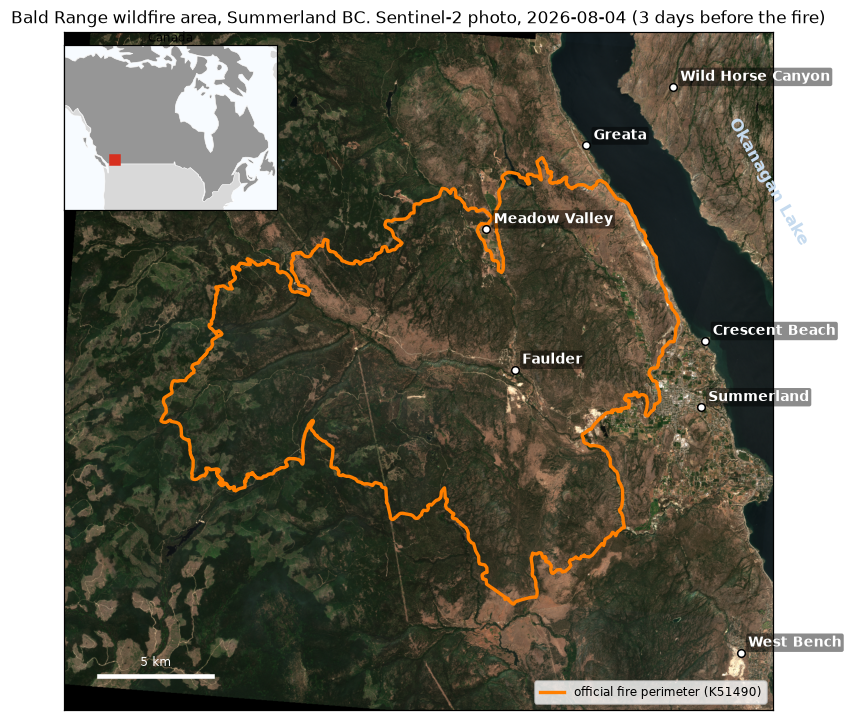

In [6]:
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(photo_A_rgb, extent=extent(GRID_A))
draw_outline(ax, perimeter_A, GRID_A, lw=2.2, label="official fire perimeter (K51490)")
for _, t in places_A.to_crs(UTM_A).iterrows():
    ax.plot(t.geometry.x, t.geometry.y, "o", ms=5, mfc="white", mec="black")
    ax.annotate(t["name"], (t.geometry.x, t.geometry.y), xytext=(5, 4), textcoords="offset points",
                color="white", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.15", fc="black", alpha=0.45, lw=0))
lx, ly = lonlat_to_grid(GRID_A, -119.655, 49.665)
ax.annotate("Okanagan Lake", (lx, ly), color="#c6dbef", fontsize=11, fontweight="bold", rotation=-60)
ax.set_xlim(extent(GRID_A)[:2])
ax.set_ylim(extent(GRID_A)[2:])
clean_axes(ax, f"Bald Range wildfire area, Summerland BC. Sentinel-2 photo, {PHOTO_BEFORE_A} (3 days before the fire)")
ax.legend(loc="lower right", fontsize=8)
scale_bar(ax)

inset = ax.inset_axes([0.0, 0.72, 0.30, 0.28])
world.plot(ax=inset, color="#d9d9d9", edgecolor="white", lw=0.4)
world[world["NAME"] == "Canada"].plot(ax=inset, color="#969696", edgecolor="white", lw=0.4)
inset.plot(np.mean(BBOX_A[::2]), np.mean(BBOX_A[1::2]), "s", color="#d7301f", ms=6)
inset.set_xlim(-141, -52)
inset.set_ylim(40, 72)
for f in (inset.set_xticks, inset.set_yticks):
    f([])
inset.set_xlabel("")
inset.set_ylabel("")
inset.set_facecolor("#f7fbff")
inset.set_title("Canada", fontsize=8, pad=2)
plt.show()

## A2. The NISAR data and how we fetch it

| | |
|---|---|
| Satellite | NISAR (NASA and ISRO), launched July 2025 |
| Radar | **L-band**, 24 cm wavelength: passes through smoke and reaches into the canopy |
| Product | **GCOV level 2** (calibrated backscatter on a map grid), collection `NISAR_L2_GCOV_PROVISIONAL_V1` |
| Pixel | delivered at 10 m here; we average 2 x 2 pixels to 20 m |
| Channels used | **HV** (main) and HH (for comparison) |
| Archive | NASA Earthdata (Alaska Satellite Facility), free account, password in `~/.netrc` |

**Why HV for a forest fire.** The radar sends a horizontal wave (H) and listens in two ways:
- **HV** (horizontal sent, vertical received) only comes back when the wave bounces many times inside a **volume** of leaves, needles and branches. It measures the **canopy**. When the canopy burns, there is less to bounce in, so **HV drops**.
- **HH** reacts more to the ground, trunks and moisture. In case 2 it was the flood channel; here it is shown for comparison only.

The search below asks NASA's catalogue (CMR) for every NISAR file over the box from June to mid-November 2026.

In [7]:
files_A = nisar_files(BBOX_A, "2026-06-01", "2026-11-14")
print(f"{len(files_A)} NISAR files touch the box, per pass (track and frame):")
print(files_A.groupby(["track", "frame"]).date.nunique().rename("dates").to_string())

65 NISAR files touch the box, per pass (track and frame):
track  frame
005A   026       9
       027       9
071D   063      10
       064      10
077A   027       9
149A   027       9
172D   063       9


Several passes cover the fire. We keep **track 071D, frame 063** (descending orbit): it covers the whole perimeter on every date, gives the same acquisition mode on all 10 dates (June 19 to October 17), and has a pass **13 days before ignition (July 25)**. No pass is closer: NISAR has no data between July 27 and August 10, 2026.

| Role | Date | Why |
|---|---|---|
| **Before** | **2026-07-25** | last pass before the fire started (August 7) |
| **After** | **2026-09-11** | the fire is out (perimeter final on August 29); the August 30 pass is wet after rain and misses part of the area |

In [8]:
use_A = files_A[(files_A.track == "071D") & (files_A.frame == "063") & (files_A.channels == "DHDH") & files_A.full_frame]
use_A = use_A.drop_duplicates("date").reset_index(drop=True)
DATES_A = list(use_A.date)
BEFORE_A, AFTER_A = "2026-07-25", "2026-09-11"
use_A[["date", "mode", "channels", "file"]]

,date,mode,channels,file
0,2026-06-19,4005,DHDH,NISAR_L2_PR_GCOV_023_071_D_063_4005_DHDH_A_202...
1,2026-07-01,4005,DHDH,NISAR_L2_PR_GCOV_024_071_D_063_4005_DHDH_A_202...
2,2026-07-13,4005,DHDH,NISAR_L2_PR_GCOV_025_071_D_063_4005_DHDH_A_202...
3,2026-07-25,4005,DHDH,NISAR_L2_PR_GCOV_026_071_D_063_4005_DHDH_A_202...
4,2026-08-18,4005,DHDH,NISAR_L2_PR_GCOV_028_071_D_063_4005_DHDH_A_202...
5,2026-08-30,4005,DHDH,NISAR_L2_PR_GCOV_029_071_D_063_4005_DHDH_A_202...
6,2026-09-11,4005,DHDH,NISAR_L2_PR_GCOV_030_071_D_063_4005_DHDH_A_202...
7,2026-09-23,4005,DHDH,NISAR_L2_PR_GCOV_031_071_D_063_4005_DHDH_A_202...
8,2026-10-05,4005,DHDH,NISAR_L2_PR_GCOV_032_071_D_063_4005_DHDH_A_202...
9,2026-10-17,4005,DHDH,NISAR_L2_PR_GCOV_033_071_D_063_4005_DHDH_A_202...


### Reading each date

For each date: open the file over HTTPS, keep the box, average the 10 m pixels to 20 m (as echo power, before converting), put it on our grid and convert to **decibels**:

$$\text{dB} = 10 \cdot \log_{10}(\text{echo power})$$

The first run streams about 50 seconds per date from NASA; the result is cached in `data/case3/cache/`.

In [9]:
earthaccess.login(strategy="netrc")
scenes = [load_date(KEY_A, r, GRID_A) for _, r in use_A.iterrows()]
RAW_A = xr.concat(scenes, dim=pd.Index(DATES_A, name="date")).rio.write_crs(UTM_A)   # HH and HV (dB) as delivered
del scenes
pd.DataFrame({"date": DATES_A,
              "valid pixels in the box %": [round(float(np.isfinite(RAW_A.HV.sel(date=d)).mean() * 100), 1) for d in DATES_A],
              "perimeter covered %": [round(float(np.isfinite(RAW_A.HV.sel(date=d).values[INSIDE_A]).mean() * 100), 1) for d in DATES_A]})

,date,valid pixels in the box %,perimeter covered %
0,2026-06-19,90.9,100.0
1,2026-07-01,85.2,100.0
2,2026-07-13,94.1,100.0
3,2026-07-25,88.3,100.0
4,2026-08-18,88.0,100.0
5,2026-08-30,73.7,97.3
6,2026-09-11,77.9,99.7
7,2026-09-23,76.4,99.1
8,2026-10-05,69.2,91.9
9,2026-10-17,61.3,75.4


## A3. The raw radar: before and after

HV on the same grey scale on both dates (-25 dB black, -5 dB white), with the official perimeter in orange. Forest is bright in HV (a lot of canopy to bounce in); lakes, bare rock and open grassland are dark. Look inside the perimeter: some areas got **darker** after the fire, while the change is small elsewhere.

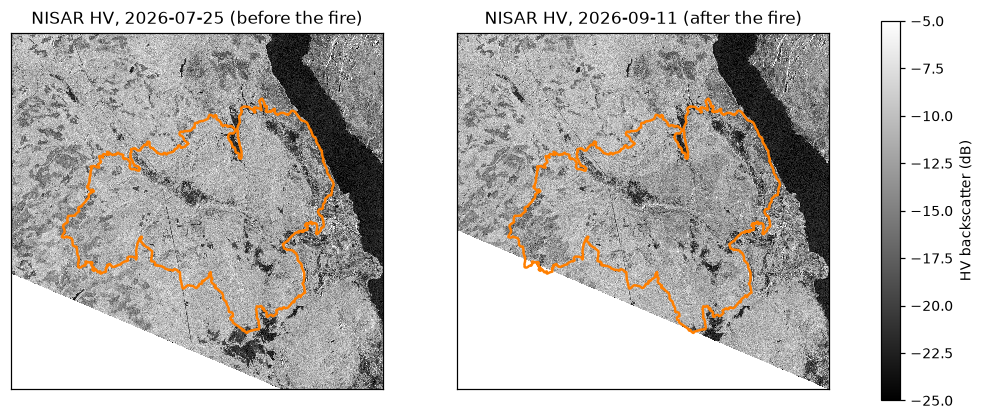

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.6))
for ax, d, label in zip(axes, (BEFORE_A, AFTER_A), ("before the fire", "after the fire")):
    im = show_radar(ax, GRID_A, RAW_A.HV.sel(date=d), f"NISAR HV, {d} ({label})")
    draw_outline(ax, perimeter_A, GRID_A)
    scale_bar(ax)
fig.colorbar(im, ax=axes, shrink=0.8, label="HV backscatter (dB)")
plt.show()

### Speckle, and how we clean it

As in case 2, each radar pixel is grainy (**speckle**): a pixel can jump by several dB with no change on the ground. We replace each pixel by the **median of the 5 x 5 pixels** around it (100 m by 100 m). All rules use this cleaned image; the raw one is kept to compare in the app.

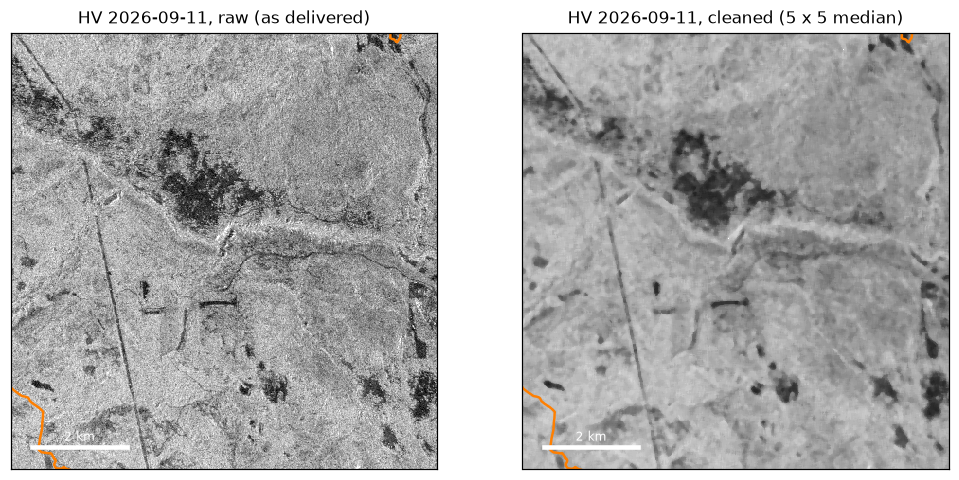

In [11]:
CLEAN_A = xr.Dataset({b: xr.concat([despeckle(RAW_A[b].sel(date=d)) for d in DATES_A], dim=pd.Index(DATES_A, name="date"))
                      for b in ("HH", "HV")}).rio.write_crs(UTM_A)

ZOOM_A = (-119.90, 49.57, -119.78, 49.65)   # about 9 km x 9 km in the middle of the burn, used for close-ups
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
for ax, img, label in zip(axes, (RAW_A, CLEAN_A), ("raw (as delivered)", "cleaned (5 x 5 median)")):
    show_radar(ax, GRID_A, img.HV.sel(date=AFTER_A), f"HV {AFTER_A}, {label}")
    draw_outline(ax, perimeter_A, GRID_A)
    zoom_to(ax, GRID_A, *ZOOM_A)
    scale_bar(ax, km=2)
plt.show()

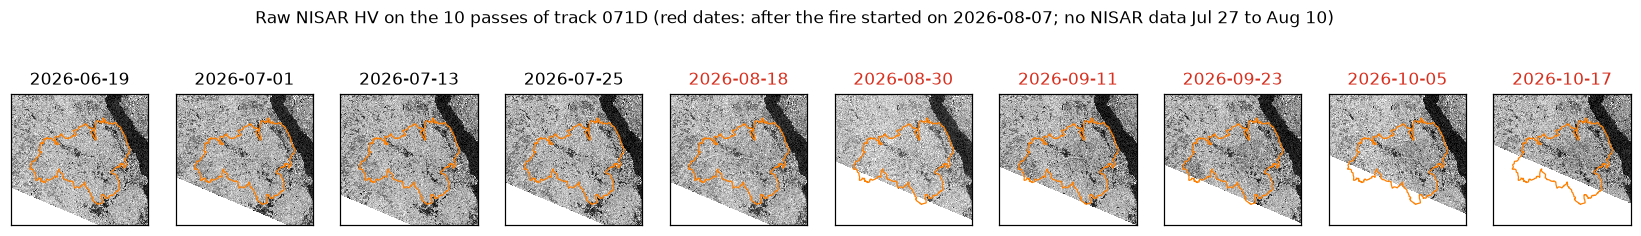

In [12]:
fig, axes = plt.subplots(1, len(DATES_A), figsize=(1.9 * len(DATES_A), 2.4))
for ax, d in zip(axes, DATES_A):
    show_radar(ax, GRID_A, RAW_A.HV.sel(date=d).values[::2, ::2], d)
    draw_outline(ax, perimeter_A, GRID_A, lw=0.8)
    ax.title.set_color("#d7301f" if d > FIRE_START_A else "black")
fig.suptitle(f"Raw NISAR HV on the {len(DATES_A)} passes of track 071D (red dates: after the fire started on {FIRE_START_A}; no NISAR data Jul 27 to Aug 10)", y=1.06)
plt.show()

## A4. What a fire does to the radar echo

| Situation | HV (canopy) | HH | What we do |
|---|---|---|---|
| **Canopy burned** (crown fire, moderate to high severity) | **drops**: fewer needles and branches for the wave to bounce in | small change | this is what we map |
| Light ground fire (canopy still there) | little change | little change | not visible to the radar |
| **Rain, wet ground or a calibration shift** | rises or falls **everywhere at once** | same | removed by comparing with the unburned forest around the fire (section A5) |
| **Logging, clear-cut** | drops too | changes | checked with the timing (section A8) and the official perimeter (section A7) |

The graph below follows the median HV and HH, on every date, in two zones: **inside the official perimeter**, and in a **ring of unburned forest 1 to 6 km outside it**. Both zones move up and down together (for example on August 30, after rain); what matters is the **gap between them**, which shrinks after the fire.

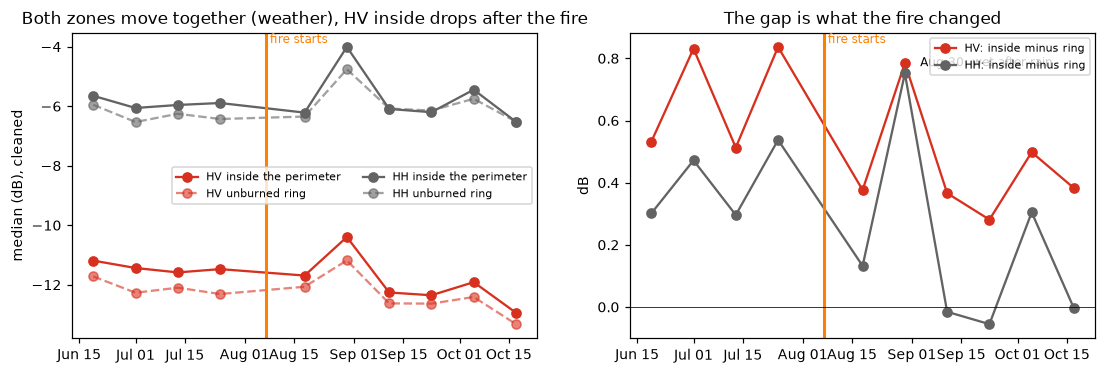

,HV inside,HV ring,HH inside,HH ring
2026-06-19,-11.19,-11.72,-5.65,-5.95
2026-07-01,-11.44,-12.27,-6.06,-6.53
2026-07-13,-11.58,-12.10,-5.96,-6.25
2026-07-25,-11.47,-12.31,-5.89,-6.43
2026-08-18,-11.69,-12.07,-6.21,-6.35
2026-08-30,-10.40,-11.18,-4.01,-4.76
2026-09-11,-12.26,-12.63,-6.09,-6.07
2026-09-23,-12.35,-12.63,-6.20,-6.14
2026-10-05,-11.91,-12.41,-5.44,-5.75
2026-10-17,-12.94,-13.32,-6.52,-6.52


In [13]:
dist_A = ndimage.distance_transform_edt(~INSIDE_A) * PIXEL_M
RING_A = (dist_A > 1000) & (dist_A < 6000)   # unburned forest around the fire, our reference zone

zones = pd.DataFrame({f"{b} {name}": [float(np.nanmedian(CLEAN_A[b].sel(date=d).values[mask])) for d in DATES_A]
                      for b in ("HV", "HH") for name, mask in (("inside", INSIDE_A), ("ring", RING_A))},
                     index=pd.to_datetime(DATES_A))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for b, color in (("HV", "#d7301f"), ("HH", "#636363")):
    axes[0].plot(zones.index, zones[f"{b} inside"], "o-", color=color, label=f"{b} inside the perimeter")
    axes[0].plot(zones.index, zones[f"{b} ring"], "o--", color=color, alpha=0.6, label=f"{b} unburned ring")
    axes[1].plot(zones.index, zones[f"{b} inside"] - zones[f"{b} ring"], "o-", color=color, label=f"{b}: inside minus ring")
for ax in axes:
    ax.axvline(pd.Timestamp(FIRE_START_A), color="#ff7f00", lw=2)
    ax.text(pd.Timestamp(FIRE_START_A), ax.get_ylim()[1], " fire starts", color="#ff7f00", va="top", fontsize=8)
    ax.xaxis.set_major_formatter(__import__("matplotlib.dates").dates.DateFormatter("%b %d"))
axes[0].set_ylabel("median (dB), cleaned")
axes[0].set_title("Both zones move together (weather), HV inside drops after the fire")
axes[0].legend(fontsize=7, ncol=2)
axes[1].set_ylabel("dB")
axes[1].axhline(0, color="black", lw=0.5)
axes[1].set_title("The gap is what the fire changed")
axes[1].annotate("Aug 30: wet after rain", (pd.Timestamp("2026-08-30"), (zones["HV inside"] - zones["HV ring"])["2026-08-30"]),
                 xytext=(10, -2), textcoords="offset points", fontsize=8)
axes[1].legend(fontsize=7)
plt.show()
zones.round(2)

## A5. Choosing the thresholds from the data

### A5a. Relative change

For every pixel we compute the change of HV between the two dates, in dB:

$$\Delta HV = HV(\text{Sep 11}) - HV(\text{Jul 25})$$

Then we remove the **common change** of the scene: the median ΔHV of the unburned ring. What is left is the change **specific to that pixel**:

$$\Delta HV_{relative} = \Delta HV - \text{median}(\Delta HV \text{ in the unburned ring})$$

Remember that a difference in dB is a ratio: **-1 dB means the canopy echo fell by about 20 %**, -2 dB by about 37 %, -3 dB by half.

Common change of the unburned ring, 2026-07-25 -> 2026-09-11: +0.10 dB (removed from every pixel)


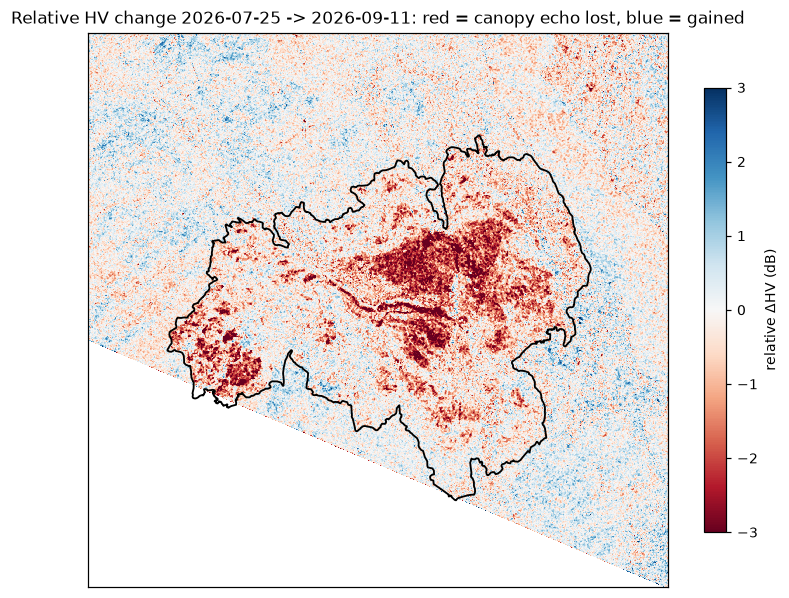

In [14]:
def relative_change(clean, band, before, after, reference):
    """Change in dB between two dates, minus the median change of the reference (unburned) zone."""
    b, a = clean[band].sel(date=before).values, clean[band].sel(date=after).values
    valid = np.isfinite(a) & np.isfinite(b)
    change = a - b
    common = float(np.nanmedian(change[reference & valid]))
    return change - common, common, valid


REL_A, COMMON_A, VALID_A = relative_change(CLEAN_A, "HV", BEFORE_A, AFTER_A, RING_A)
print(f"Common change of the unburned ring, {BEFORE_A} -> {AFTER_A}: {COMMON_A:+.2f} dB (removed from every pixel)")

fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(np.where(VALID_A, REL_A, np.nan), cmap="RdBu", vmin=-3, vmax=3, extent=extent(GRID_A), interpolation="nearest")
draw_outline(ax, perimeter_A, GRID_A, color="black", lw=1.2)
scale_bar(ax)
clean_axes(ax, f"Relative HV change {BEFORE_A} -> {AFTER_A}: red = canopy echo lost, blue = gained")
fig.colorbar(im, ax=ax, shrink=0.75, label="relative ΔHV (dB)")
plt.show()

### A5b. How much does HV move when nothing burns?

In the unburned ring the relative change is never exactly 0 (leftover speckle, moisture, small forest changes). We measure that **normal movement** (its spread, the standard deviation) and set two thresholds, rounded to a whole dB:
- **canopy loss**: a drop of at least **2 times** the normal movement;
- **severe canopy loss**: a drop of at least **3 times** the normal movement.

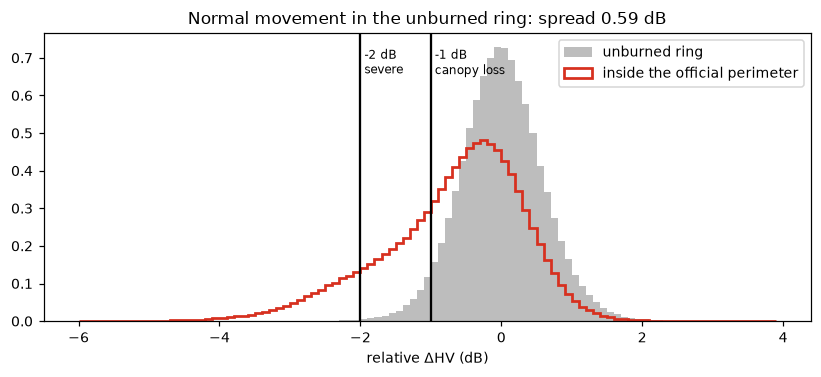

,threshold,unburned ring pixels below it %,pixels inside the perimeter below it %
0,-1 dB (canopy loss),4.0,32.0
1,-2 dB (severe),0.1,11.4


In [15]:
ring_rel = REL_A[RING_A & VALID_A]
inside_rel = REL_A[INSIDE_A & VALID_A]
NOISE_A = float(np.std(ring_rel))
T_LOSS = max(1.0, float(np.round(2 * NOISE_A)))
T_SEVERE = max(T_LOSS + 1, float(np.round(3 * NOISE_A)))

fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.arange(-6, 4, 0.1)
ax.hist(ring_rel, bins=bins, density=True, color="#bdbdbd", label="unburned ring")
ax.hist(inside_rel, bins=bins, density=True, histtype="step", lw=1.8, color="#d7301f", label="inside the official perimeter")
for t, name in ((T_LOSS, "canopy loss"), (T_SEVERE, "severe")):
    ax.axvline(-t, color="black", lw=1.5)
    ax.text(-t, ax.get_ylim()[1] * 0.95, f" -{t:.0f} dB\n {name}", fontsize=8, va="top")
ax.set_xlabel("relative ΔHV (dB)")
ax.set_title(f"Normal movement in the unburned ring: spread {NOISE_A:.2f} dB")
ax.legend(loc="upper right")
plt.show()

pd.DataFrame({"threshold": [f"-{T_LOSS:.0f} dB (canopy loss)", f"-{T_SEVERE:.0f} dB (severe)"],
              "unburned ring pixels below it %": [round(100 * (ring_rel <= -t).mean(), 1) for t in (T_LOSS, T_SEVERE)],
              "pixels inside the perimeter below it %": [round(100 * (inside_rel <= -t).mean(), 1) for t in (T_LOSS, T_SEVERE)]})

The inside of the perimeter is shifted to the left (more drops), but most of it overlaps the unburned ring: many areas inside the official perimeter only burned lightly, under a canopy that survived. The radar maps where the **canopy itself** was lost.

## A6. The rules and their map

Per pixel, with the cleaned HV on July 25 (before) and September 11 (after):

| Rule | Test | Meaning | Colour |
|---|---|---|---|
| vegetated before | HV(before) > -18 dB | there was a canopy to lose (excludes lakes, rock, bare ground) | |
| **canopy loss** | relative ΔHV ≤ -T_loss | the canopy echo fell clearly more than normal | yellow `#fec44f` |
| **severe canopy loss** | relative ΔHV ≤ -T_severe | the canopy echo fell strongly | red `#d7301f` |

As in case 2, single pixels can fire on speckle alone, so we keep a pixel only if it belongs to a **patch of at least 9 pixels** (0.36 ha).

In [16]:
BURN_COLORS = {1: "#fec44f", 2: "#d7301f"}
BURN_LABELS = {0: "no canopy change", 1: "canopy loss", 2: "severe canopy loss"}
VEG_MIN_DB = -18.0      # HV before above this: there was vegetation
MIN_PATCH_PX = 9        # 3 x 3 pixels = 0.36 ha
NODATA = 255


def keep_patches(mask):
    """Keep pixels of `mask` that belong to connected patches of at least MIN_PATCH_PX pixels."""
    labels, _ = ndimage.label(mask, structure=np.ones((3, 3)))
    size = np.bincount(labels.ravel())
    ok = size >= MIN_PATCH_PX
    ok[0] = False
    return ok[labels]


def burn_codes(clean, before, after, rel, valid):
    """Burn map: 0 no change, 1 canopy loss, 2 severe canopy loss, 255 no data."""
    vegetated = clean["HV"].sel(date=before).values > VEG_MIN_DB
    loss = keep_patches(valid & vegetated & (rel <= -T_LOSS))
    severe = loss & (rel <= -T_SEVERE)
    codes = np.where(severe, 2, np.where(loss, 1, 0)).astype("uint8")
    codes[~valid] = NODATA
    return codes


def km2(mask):
    return round(float(mask.sum()) * PIXEL_M**2 / 1e6, 1)


CODES_A = burn_codes(CLEAN_A, BEFORE_A, AFTER_A, REL_A, VALID_A)
areas_A = pd.DataFrame({zone: {BURN_LABELS[k]: km2((CODES_A == k) & m) for k in (1, 2)}
                        for zone, m in (("whole box", np.ones_like(INSIDE_A)), ("inside official perimeter", INSIDE_A),
                                        ("outside perimeter", ~INSIDE_A))})
areas_A.index.name = "km²"
areas_A

,whole box,inside official perimeter,outside perimeter
km²,,,
canopy loss,53.6,45.7,7.9
severe canopy loss,29.0,28.5,0.6


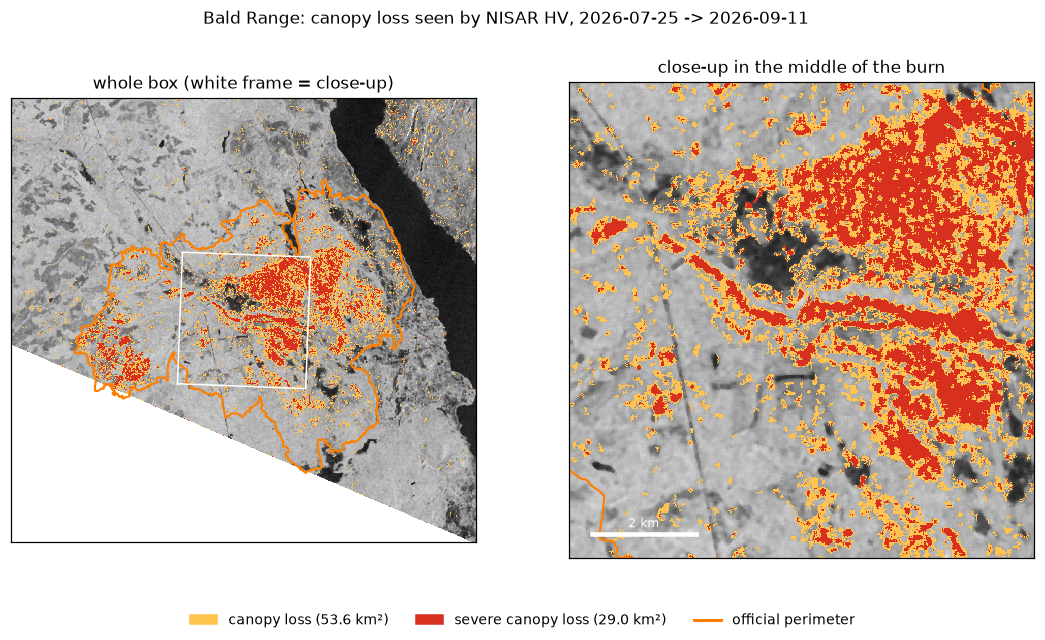

In [17]:
def burn_figure(grid, clean_after, codes, perimeter, zoom, title):
    """Whole box (left) and close-up (right): burn classes over the cleaned HV after the fire."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 5.8))
    for ax, z in zip(axes, (None, zoom)):
        show_radar(ax, grid, clean_after, "")
        show_classes(ax, grid, codes, BURN_COLORS)
        draw_outline(ax, perimeter, grid, lw=1.4)
        if z:
            zoom_to(ax, grid, *z)
            scale_bar(ax, km=2)
        else:
            ax.plot(*box_xy(grid, *zoom), color="white", lw=1)
            scale_bar(ax)
    axes[0].set_title("whole box (white frame = close-up)")
    axes[1].set_title("close-up in the middle of the burn")
    handles = [Patch(color=BURN_COLORS[k], label=f"{BURN_LABELS[k]} ({km2(codes == k)} km²)") for k in BURN_COLORS]
    handles.append(__import__("matplotlib.lines").lines.Line2D([], [], color="#ff7f00", lw=2, label="official perimeter"))
    fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(title, y=0.98)
    plt.show()
    plt.close(fig)


burn_figure(GRID_A, CLEAN_A.HV.sel(date=AFTER_A), CODES_A, perimeter_A, ZOOM_A,
            f"Bald Range: canopy loss seen by NISAR HV, {BEFORE_A} -> {AFTER_A}")

## A7. Checking the result against two independent references

### A7a. The official fire perimeter

The BC Wildfire Service perimeter (K51490) was mapped by the fire crews, from the air and on the ground. Two questions:
- **Where does the radar find canopy loss?** If it is a fire signal, it should be almost all **inside** the perimeter.
- **How much of the perimeter does it flag?** Not all of it: a perimeter is the outer line of the fire and includes unburned islands and lightly burned ground.

In [18]:
burned_A = (CODES_A == 1) | (CODES_A == 2)
valid_inside = INSIDE_A & VALID_A
pd.Series({
    "radar canopy loss, total (km²)": km2(burned_A),
    "of which inside the official perimeter (%)": round(100 * (burned_A & INSIDE_A).sum() / burned_A.sum(), 1),
    "official perimeter seen by the radar (km²)": km2(valid_inside),
    "share of the perimeter flagged as canopy loss (%)": round(100 * (burned_A & INSIDE_A).sum() / valid_inside.sum(), 1),
    "canopy loss outside the perimeter (km²)": km2(burned_A & ~INSIDE_A),
}, name="Bald Range, " + f"{BEFORE_A} -> {AFTER_A}").to_frame()

,"Bald Range, 2026-07-25 -> 2026-09-11"
"radar canopy loss, total (km²)",82.7
of which inside the official perimeter (%),89.7
official perimeter seen by the radar (km²),251.1
share of the perimeter flagged as canopy loss (%),29.6
canopy loss outside the perimeter (km²),8.5


### A7b. Burn severity from Sentinel-2 (optical)

Optical satellites measure burn severity with the **Normalized Burn Ratio**. Healthy vegetation reflects a lot of near infrared (NIR) and little short-wave infrared (SWIR); burned ground does the opposite:

$$NBR = \frac{NIR - SWIR}{NIR + SWIR} \qquad dNBR = NBR(\text{before}) - NBR(\text{after})$$

We use two cloud-free Sentinel-2 images: **August 4** (before) and **September 18** (after, once the smoke cleared). The dNBR classes are the standard ones of the US Geological Survey (Key and Benson): below 0.1 unburned, 0.1 to 0.27 low, 0.27 to 0.44 moderate-low, 0.44 to 0.66 moderate-high, above 0.66 high severity.

This is a completely independent measurement (sunlight reflected by the ground, not radar), so it is a fair test of the radar map.

In [19]:
def sentinel2_band(key, grid, bbox, day, asset):
    """One Sentinel-2 band as surface reflectance (0 to 1) on the grid, cached."""
    path = CACHE / f"{key}_sentinel2_{day}_{asset}.tif"
    if not path.exists():
        items = sorted(stac_search("sentinel-2-l2a", bbox, day), key=lambda f: f["properties"]["eo:cloud_cover"])
        out = None
        for item in items:
            tile = rioxarray.open_rasterio(item["assets"][asset]["href"]).squeeze(drop=True)
            try:
                tile = tile.rio.clip_box(*bbox, crs="EPSG:4326")
            except Exception:
                continue
            part = tile.rio.reproject_match(grid, nodata=0).values.astype("float32")
            info = item["assets"][asset]["raster:bands"][0]
            # digital number -> reflectance; the catalogue says when its offset is already applied to the numbers
            offset = 0.0 if item["properties"].get("earthsearch:boa_offset_applied") else info.get("offset", 0.0)
            part = np.where(part > 0, part * info.get("scale", 1e-4) + offset, np.nan)
            out = part if out is None else np.where(np.isfinite(out), out, part)
        grid.copy(data=out.astype("float32")).rio.to_raster(path, compress="deflate")
    return rioxarray.open_rasterio(path).squeeze(drop=True).values


PHOTO_AFTER_A = "2026-09-18"
nbr = {}
for day in (PHOTO_BEFORE_A, PHOTO_AFTER_A):
    nir, swir = sentinel2_band(KEY_A, GRID_A, BBOX_A, day, "nir08"), sentinel2_band(KEY_A, GRID_A, BBOX_A, day, "swir22")
    nbr[day] = (nir - swir) / (nir + swir)
DNBR_A = nbr[PHOTO_BEFORE_A] - nbr[PHOTO_AFTER_A]

SEVERITY = [(-np.inf, 0.10, "unburned"), (0.10, 0.27, "low"), (0.27, 0.44, "moderate-low"),
            (0.44, 0.66, "moderate-high"), (0.66, np.inf, "high")]
SEVERITY_COLORS = ["#f0f0f0", "#ffffb2", "#fecc5c", "#fd8d3c", "#bd0026"]
severity_A = np.full(DNBR_A.shape, -1)
for i, (lo, hi, _) in enumerate(SEVERITY):
    severity_A[(DNBR_A >= lo) & (DNBR_A < hi)] = i

rows = []
for i, (lo, hi, name) in enumerate(SEVERITY):
    m = (severity_A == i) & VALID_A
    rows.append({"optical burn severity (dNBR)": name, "area in the box (km²)": km2(m),
                 "radar relative ΔHV, median (dB)": round(float(np.median(REL_A[m])), 2),
                 "flagged canopy loss by the radar %": round(100 * burned_A[m].mean(), 1),
                 "flagged severe by the radar %": round(100 * (CODES_A[m] == 2).mean(), 1)})
pd.DataFrame(rows)

,optical burn severity (dNBR),area in the box (km²),"radar relative ΔHV, median (dB)",flagged canopy loss by the radar %,flagged severe by the radar %
0,unburned,477.7,0.02,1.9,0.1
1,low,106.4,-0.16,6.2,0.5
2,moderate-low,54.9,-0.41,16.8,2.4
3,moderate-high,42.0,-1.01,48.5,15.2
4,high,45.9,-1.86,81.7,44.0


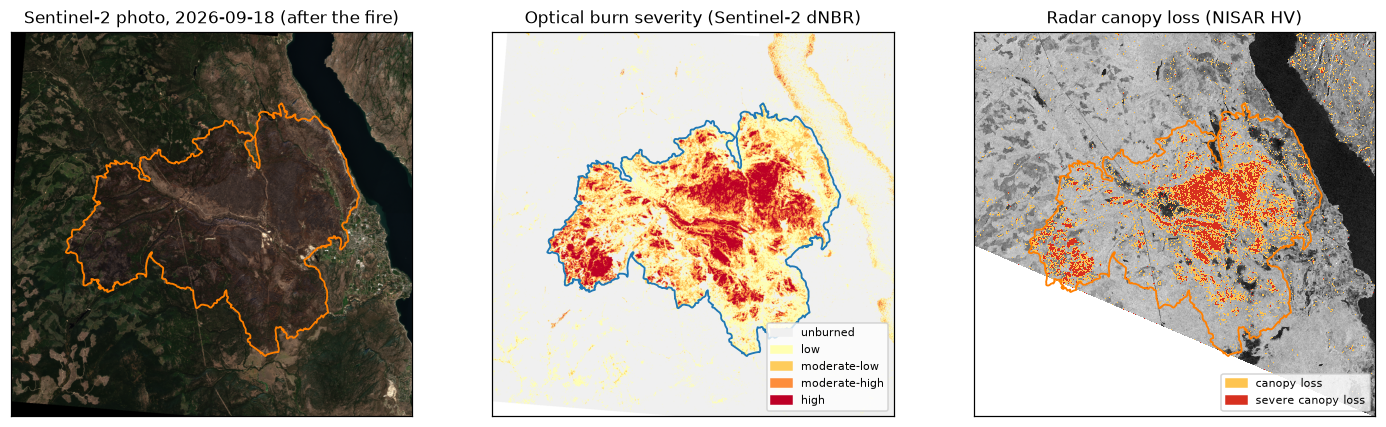

In [20]:
photo_after_A = sentinel2_photo(KEY_A, GRID_A, BBOX_A, PHOTO_AFTER_A)
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
axes[0].imshow(np.moveaxis(photo_after_A.values, 0, -1), extent=extent(GRID_A))
clean_axes(axes[0], f"Sentinel-2 photo, {PHOTO_AFTER_A} (after the fire)")
sev_rgba = np.zeros(DNBR_A.shape + (4,), "uint8")
for i, c in enumerate(SEVERITY_COLORS):
    sev_rgba[severity_A == i] = [int(c[j:j + 2], 16) for j in (1, 3, 5)] + [255]
axes[1].imshow(sev_rgba, extent=extent(GRID_A))
clean_axes(axes[1], "Optical burn severity (Sentinel-2 dNBR)")
show_radar(axes[2], GRID_A, CLEAN_A.HV.sel(date=AFTER_A), "Radar canopy loss (NISAR HV)")
show_classes(axes[2], GRID_A, CODES_A, BURN_COLORS)
for ax in axes:
    draw_outline(ax, perimeter_A, GRID_A, color="#1f78b4" if ax is axes[1] else "#ff7f00", lw=1.2)
    ax.set_xlim(extent(GRID_A)[:2])
    ax.set_ylim(extent(GRID_A)[2:])
axes[1].legend(handles=[Patch(color=c, label=s[2]) for c, s in zip(SEVERITY_COLORS, SEVERITY)], loc="lower right", fontsize=7)
axes[2].legend(handles=[Patch(color=BURN_COLORS[k], label=BURN_LABELS[k]) for k in BURN_COLORS], loc="lower right", fontsize=7)
plt.show()

**How to read it.** The radar and the optical index agree where the fire was strongest: most **high-severity** pixels are flagged by the radar, and almost none of the unburned ones. Low-severity burns (fire on the ground, canopy still standing) are mostly not flagged: the canopy the radar measures is still there. So the radar map answers a precise question: **where did the forest canopy burn?**

## A8. Time series: is the drop really the fire?

A clear-cut or a storm can also lower HV. A fire has a **date**: the canopy loss must appear **after August 7**, not before. We apply the same rules (same thresholds) to every date, always compared with July 25, and count the canopy loss inside and outside the official perimeter.

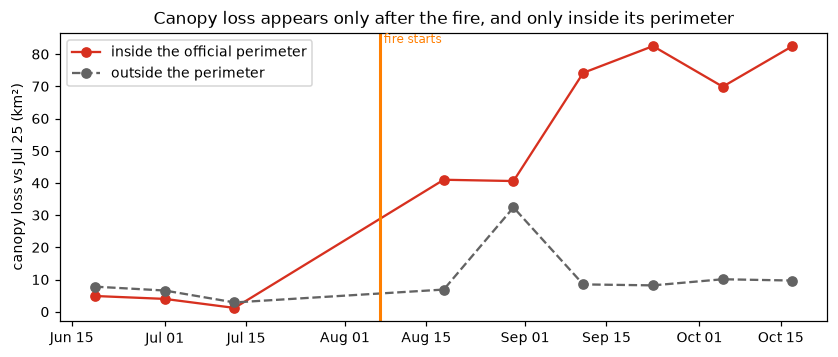

,inside perimeter (km²),outside perimeter (km²),perimeter covered %
date,,,
2026-06-19,4.9,7.8,100.0
2026-07-01,4.0,6.6,100.0
2026-07-13,1.2,2.9,100.0
2026-08-18,41.0,6.9,100.0
2026-08-30,40.6,32.4,97.3
2026-09-11,74.2,8.5,99.7
2026-09-23,82.5,8.2,99.1
2026-10-05,69.9,10.1,91.9
2026-10-17,82.5,9.7,75.4


In [21]:
series = []
for d in DATES_A:
    if d == BEFORE_A:
        continue
    rel, _, valid = relative_change(CLEAN_A, "HV", BEFORE_A, d, RING_A)
    codes = burn_codes(CLEAN_A, BEFORE_A, d, rel, valid)
    loss = (codes == 1) | (codes == 2)
    series.append({"date": d, "inside perimeter (km²)": km2(loss & INSIDE_A), "outside perimeter (km²)": km2(loss & ~INSIDE_A),
                   "perimeter covered %": round(100 * (valid & INSIDE_A).sum() / INSIDE_A.sum(), 1)})
    if d == AFTER_A:
        assert np.array_equal(codes, CODES_A)
series_A = pd.DataFrame(series).set_index("date")

fig, ax = plt.subplots(figsize=(9, 3.4))
t = pd.to_datetime(series_A.index)
ax.plot(t, series_A["inside perimeter (km²)"], "o-", color="#d7301f", label="inside the official perimeter")
ax.plot(t, series_A["outside perimeter (km²)"], "o--", color="#636363", label="outside the perimeter")
ax.axvline(pd.Timestamp(FIRE_START_A), color="#ff7f00", lw=2)
ax.text(pd.Timestamp(FIRE_START_A), ax.get_ylim()[1], " fire starts", color="#ff7f00", va="top", fontsize=8)
ax.xaxis.set_major_formatter(__import__("matplotlib.dates").dates.DateFormatter("%b %d"))
ax.set_ylabel("canopy loss vs Jul 25 (km²)")
ax.set_title("Canopy loss appears only after the fire, and only inside its perimeter")
ax.legend()
plt.show()
series_A

Before the fire (June and July compared with July 25), the rules find only a few km² everywhere: that is the background of false alarms. From the first pass after ignition (August 18, while the fire was still burning) the canopy loss inside the perimeter jumps, then levels off at about 75 to 80 km² once the fire is out, while outside the perimeter it stays at the background level. Two exceptions, both explained: the August 30 pass is wet after rain (false alarms rise everywhere, inside and outside), and the October 5 pass misses part of the perimeter (see the coverage column).

## A9. Export for the app

Everything the app needs for this fire is written to `data/case3/export/bald_range/` (about 15 MB; committed to git). Same format as case 2: images ready to lay on a web map, numbers in JSON, no Python needed.

```
data/case3/export/bald_range/
  manifest.json                          what everything is: dates, key dates, corners, legend, colours, encodings, file list
  stats.json                             km² per class and per date, thresholds and how they were chosen, validation numbers
  README.md                              this section, for the developer
  reference/sentinel2_2026-08-04.webp    satellite photo before the fire
  reference/sentinel2_2026-09-18.webp    satellite photo after the fire
  reference/burn_severity_optical.png    Sentinel-2 burn severity (dNBR), for comparison
  reference/perimeter.geojson            official BC Wildfire Service fire perimeter K51490 (lon/lat)
  reference/places.geojson               place names (lon/lat)
  radar/hv_raw_<date>.webp               10 images: HV as delivered, grey
  radar/hv_clean_<date>.webp             10 images: HV after the speckle filter, grey (what the rules use)
  radar/hv_clean_<date>.tif              10 rasters: the same values as numbers (40 m), for a "click a pixel" tool
  burn/burn_<date>.png                   6 images: canopy loss since July 25, for every pass after the fire
  burn/burn_<date>.tif                   6 rasters: the same maps as class codes
```

**Key dates** (in `manifest.json` → `key_dates`, matching the app's case stages):

| Stage | Date | Use |
|---|---|---|
| before (lead-up) | 2026-07-25 | last radar pass before the fire; photo of 2026-08-04 |
| during (event) | 2026-08-18 | first pass after ignition, fire still burning: `burn/burn_2026-08-18.png` |
| after (takeaway) | 2026-09-11 | fire out, main result: `burn/burn_2026-09-11.png`; photo of 2026-09-18 |

**How to place the images on the map.** Every `.png` and `.webp` image is in Web Mercator (EPSG:3857) and covers the same rectangle. Its four corners are in `manifest.json` → `image_corners`, as `[lon, lat]` in the order top-left, top-right, bottom-right, bottom-left: exactly what MapLibre's `image` source expects. Transparent pixels mean "nothing here" or "no data".

**Pixel encodings**

| File | Pixel | Meaning |
|---|---|---|
| `radar/*.webp` | grey 0 to 255 (alpha 0 = no data) | dB = -25 + 20 × grey / 255 (black -25 dB, white -5 dB) |
| `radar/hv_clean_*.tif` | uint8, UTM 11N, 40 m | dB = -40 + 0.25 × value; 255 = no data |
| `burn/*.png` | colours below, or transparent | canopy loss since July 25 |
| `burn/*.tif` | uint8 code, UTM 11N, 20 m | 0 no change, 1 canopy loss, 2 severe canopy loss, 255 no data |
| `reference/burn_severity_optical.png` | colours in `manifest.json` → `optical_severity` | Sentinel-2 dNBR classes (unburned to high) |

| Code | Colour | Label |
|---|---|---|
| 1 | `#fec44f` | canopy loss (HV fell at least 1 dB more than the unburned forest) |
| 2 | `#d7301f` | severe canopy loss (at least 2 dB) |

In [22]:
WEB = 3857
HV_RANGE = (-25.0, -5.0)
VALUE_OFFSET, VALUE_STEP = -40.0, 0.25


def to_web(array, grid):
    """Grid -> Web Mercator (nearest pixel), NaN outside the data."""
    return grid.copy(data=array.astype("float32")).rio.reproject(f"EPSG:{WEB}", nodata=np.nan, resampling=0)


def web_corners(grid):
    """Corners of the Web Mercator images as [lon, lat]: top-left, top-right, bottom-right, bottom-left."""
    west, south, east, north = to_web(np.zeros(grid.shape), grid).rio.bounds()
    (w, e), (s, n) = Transformer.from_crs(WEB, 4326, always_xy=True).transform([west, east], [south, north])
    return [[w, n], [e, n], [e, s], [w, s]]


def save_grey(db, grid, path, value_range):
    w = to_web(db, grid).values
    grey = np.nan_to_num(np.clip((w - value_range[0]) / (value_range[1] - value_range[0]) * 255, 0, 255)).astype("uint8")
    alpha = np.where(np.isfinite(w), 255, 0).astype("uint8")
    Image.fromarray(np.dstack([grey, grey, grey, alpha]), "RGBA").save(path, quality=80)


def save_classes(codes, grid, colors, path):
    w = to_web(np.where(codes == NODATA, np.nan, codes), grid).values
    rgba = np.zeros(w.shape + (4,), "uint8")
    for k, hexcol in colors.items():
        rgba[w == k] = [int(hexcol[i:i + 2], 16) for i in (1, 3, 5)] + [255]
    Image.fromarray(rgba, "RGBA").save(path, optimize=True)


def save_photo(photo, grid, path):
    web = photo.rio.reproject(f"EPSG:{WEB}", nodata=0).values
    alpha = np.where(web.max(axis=0) <= 8, 0, 255).astype("uint8")
    Image.fromarray(np.dstack([*web, alpha]), "RGBA").save(path, quality=82)


def save_tif(values, path, like):
    like.copy(data=values.astype("uint8")).rio.write_nodata(NODATA).rio.to_raster(path, driver="COG", compress="deflate")


def at_40m(db):
    """Average 2 x 2 pixels: 40 m is enough for a click-a-pixel tool and the file is 4 times smaller."""
    return db.coarsen(x=2, y=2, boundary="trim").mean().rio.write_crs(db.rio.crs)


def encode_db(db):
    v = np.round((np.clip(db, VALUE_OFFSET, VALUE_OFFSET + 254 * VALUE_STEP) - VALUE_OFFSET) / VALUE_STEP)
    return np.where(np.isfinite(db), v, NODATA)

In [23]:
from PIL import Image

OUT_A = EXPORT / KEY_A
for sub in ("reference", "radar", "burn"):
    (OUT_A / sub).mkdir(parents=True, exist_ok=True)

# reference layers
save_photo(photo_A, GRID_A, OUT_A / f"reference/sentinel2_{PHOTO_BEFORE_A}.webp")
save_photo(photo_after_A, GRID_A, OUT_A / f"reference/sentinel2_{PHOTO_AFTER_A}.webp")
save_classes(np.where(np.isfinite(DNBR_A), severity_A, NODATA), GRID_A, dict(enumerate(SEVERITY_COLORS)),
             OUT_A / "reference/burn_severity_optical.png")
perimeter_A[["FIRE_NUMBER", "FIRE_SIZE_HECTARES", "TRACK_DATE", "geometry"]].assign(
    TRACK_DATE=lambda d: d["TRACK_DATE"].astype(str)).to_file(OUT_A / "reference/perimeter.geojson", driver="GeoJSON")
places_A[["name", "place", "geometry"]].to_file(OUT_A / "reference/places.geojson", driver="GeoJSON")

# radar, one per date
for d in DATES_A:
    save_grey(RAW_A.HV.sel(date=d).values, GRID_A, OUT_A / f"radar/hv_raw_{d}.webp", HV_RANGE)
    save_grey(CLEAN_A.HV.sel(date=d).values, GRID_A, OUT_A / f"radar/hv_clean_{d}.webp", HV_RANGE)
    coarse = at_40m(CLEAN_A.HV.sel(date=d))
    save_tif(encode_db(coarse.values), OUT_A / f"radar/hv_clean_{d}.tif", coarse)

# burn maps, one per pass after the fire (each compared with July 25)
BURN_DATES_A = [d for d in DATES_A if d > FIRE_START_A]
burn_km2_A = {}
for d in BURN_DATES_A:
    rel, _, valid = relative_change(CLEAN_A, "HV", BEFORE_A, d, RING_A)
    codes = burn_codes(CLEAN_A, BEFORE_A, d, rel, valid)
    save_classes(codes, GRID_A, BURN_COLORS, OUT_A / f"burn/burn_{d}.png")
    save_tif(codes, OUT_A / f"burn/burn_{d}.tif", GRID_A)
    burn_km2_A[d] = {BURN_LABELS[k]: km2(codes == k) for k in BURN_COLORS}
print("images written to", OUT_A)

images written to ../data/case3/export/bald_range


In [24]:
legend_A = {str(k): {"label": BURN_LABELS[k], "color": BURN_COLORS[k]} for k in BURN_COLORS}
stats_A = {
    "fire": {"name": "Bald Range wildfire", "fire_number": "K51490", "start": FIRE_START_A,
             "official_size_ha": float(perimeter_A.iloc[0]["FIRE_SIZE_HECTARES"])},
    "thresholds": {
        "loss_db": -T_LOSS, "severe_db": -T_SEVERE,
        "how": f"relative HV change = HV change minus the median change of an unburned ring 1 to 6 km outside the perimeter; "
               f"normal movement (standard deviation) in the ring {NOISE_A:.2f} dB; loss = 2 x, severe = 3 x, rounded",
        "common_change_db": round(COMMON_A, 2), "vegetated_min_hv_db": VEG_MIN_DB, "min_patch_pixels": MIN_PATCH_PX,
    },
    "main_result": {"before": BEFORE_A, "after": AFTER_A, **{BURN_LABELS[k]: km2(CODES_A == k) for k in BURN_COLORS},
                    "inside_perimeter_pct": round(100 * (burned_A & INSIDE_A).sum() / burned_A.sum(), 1),
                    "perimeter_flagged_pct": round(100 * (burned_A & INSIDE_A).sum() / valid_inside.sum(), 1)},
    "canopy_loss_km2_by_date": burn_km2_A,
    "time_series_inside_outside_km2": series_A.reset_index().to_dict(orient="records"),
    "optical_validation": rows,
}
manifest_A = {
    "case": "case3", "part": "A", "key": KEY_A, "title": "Bald Range wildfire, Summerland, British Columbia",
    "event_date": FIRE_START_A,
    "story": "Started Aug 7, 2026 west of Summerland; about 10,300 ha in two days, BC provincial emergency, about 150 structures "
             "damaged or destroyed; final perimeter 25,163 ha (BC Wildfire Service K51490).",
    "bbox_lonlat": list(BBOX_A),
    "image_crs": f"EPSG:{WEB}", "image_corners": web_corners(GRID_A),
    "image_corners_order": "top-left, top-right, bottom-right, bottom-left, as [lon, lat]",
    "raster_crs": f"EPSG:{UTM_A}", "pixel_m": PIXEL_M,
    "satellite": "NISAR (NASA-ISRO), L-band", "product": "NISAR_L2_GCOV_PROVISIONAL_V1", "track": "071D frame 063", "channel": "HV",
    "dates": DATES_A, "key_dates": {"before": BEFORE_A, "during": "2026-08-18", "after": AFTER_A},
    "legend": legend_A,
    "optical_severity": {s[2]: c for s, c in zip(SEVERITY, SEVERITY_COLORS)},
    "files": {
        "photo_before": {"path": f"reference/sentinel2_{PHOTO_BEFORE_A}.webp", "date": PHOTO_BEFORE_A},
        "photo_after": {"path": f"reference/sentinel2_{PHOTO_AFTER_A}.webp", "date": PHOTO_AFTER_A},
        "optical_severity": "reference/burn_severity_optical.png",
        "perimeter": "reference/perimeter.geojson", "places": "reference/places.geojson",
        "radar_raw": {d: f"radar/hv_raw_{d}.webp" for d in DATES_A},
        "radar_clean": {d: f"radar/hv_clean_{d}.webp" for d in DATES_A},
        "radar_values": {d: f"radar/hv_clean_{d}.tif" for d in DATES_A},
        "burn": {d: {"png": f"burn/burn_{d}.png", "tif": f"burn/burn_{d}.tif"} for d in BURN_DATES_A},
    },
    "encodings": {
        "radar_webp": {"db_min": HV_RANGE[0], "db_max": HV_RANGE[1], "formula": "dB = db_min + (db_max - db_min) * grey / 255", "no_data": "alpha 0"},
        "radar_tif": {"dtype": "uint8", "formula": f"dB = {VALUE_OFFSET} + {VALUE_STEP} * value", "no_data": NODATA},
        "burn_tif": {"dtype": "uint8", "codes": {"0": BURN_LABELS[0], **{k: v["label"] for k, v in legend_A.items()}}, "no_data": NODATA},
    },
}
(OUT_A / "manifest.json").write_text(json.dumps(manifest_A, indent=2, default=float))
(OUT_A / "stats.json").write_text(json.dumps(stats_A, indent=2, default=float))
print("manifest.json and stats.json written")

manifest.json and stats.json written


### Check the export

Re-open every file, check the sizes and the colours, and lay the exported burn map on the exported photo using only the corners from `manifest.json` (as the app will).

50 files, 14.9 MB


value raster round trip: max error 0.125 dB


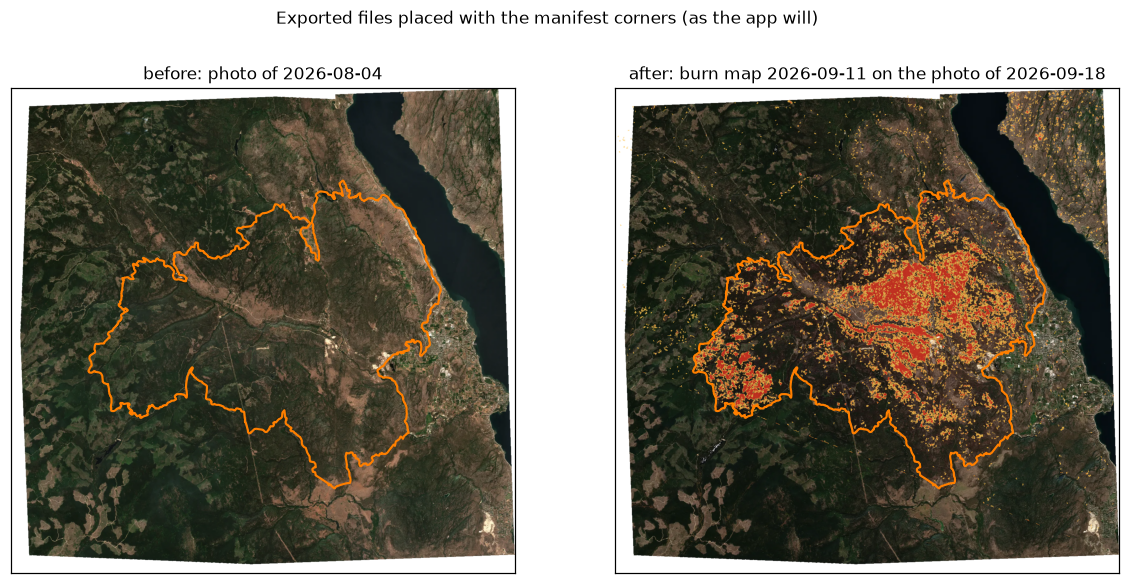

In [25]:
m = json.loads((OUT_A / "manifest.json").read_text())
files_out = sorted(p for p in OUT_A.rglob("*") if p.is_file())
print(f"{len(files_out)} files, {sum(p.stat().st_size for p in files_out) / 1e6:.1f} MB")
allowed = {tuple(int(c[i:i + 2], 16) for i in (1, 3, 5)) for c in BURN_COLORS.values()}
for d, f in m["files"]["burn"].items():
    img = np.asarray(Image.open(OUT_A / f["png"]))
    used = {tuple(px[:3]) for px in np.unique(img[img[..., 3] > 0].reshape(-1, 4), axis=0)}
    assert used <= allowed, f"unexpected colours in {f['png']}"
    assert set(np.unique(rioxarray.open_rasterio(OUT_A / f["tif"]).values)) <= {0, 1, 2, NODATA}
assert len(m["files"]["radar_raw"]) == len(DATES_A)
v = rioxarray.open_rasterio(OUT_A / m["files"]["radar_values"][AFTER_A]).values[0].astype(float)
back = np.where(v == NODATA, np.nan, VALUE_OFFSET + VALUE_STEP * v)
print(f"value raster round trip: max error {np.nanmax(np.abs(back - at_40m(CLEAN_A.HV.sel(date=AFTER_A)).values)):.3f} dB")

c = m["image_corners"]
(x0, x1), (y1, y0) = Transformer.from_crs(4326, WEB, always_xy=True).transform([c[0][0], c[1][0]], [c[0][1], c[2][1]])
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, photo, burn, title in ((axes[0], "photo_before", None, "before: photo of " + PHOTO_BEFORE_A),
                               (axes[1], "photo_after", m["key_dates"]["after"], "after: burn map " + AFTER_A + " on the photo of " + PHOTO_AFTER_A)):
    ax.imshow(Image.open(OUT_A / m["files"][photo]["path"]), extent=[x0, x1, y0, y1])
    if burn:
        ax.imshow(Image.open(OUT_A / m["files"]["burn"][burn]["png"]), extent=[x0, x1, y0, y1], alpha=0.85)
    gpd.read_file(OUT_A / m["files"]["perimeter"]).to_crs(WEB).boundary.plot(ax=ax, color="#ff7f00", lw=1.4)
    clean_axes(ax, title)
plt.suptitle("Exported files placed with the manifest corners (as the app will)")
plt.show()